# 05 - Baseline: Random Forest y XGBoost sobre features físicas

Modelos en `src/models_classic.py`; protocolo en `src/evaluation.py` (CV estratificada 5x5 sobre train, más test oficial con IC 95% por bootstrap).

Desbalance: Random Forest con `class_weight='balanced_subsample'`; XGBoost con `scale_pos_weight` = negativos/positivos del fold de entrenamiento (~136).

**Ablación por familia de features:** estadísticos / FFT / BLS / todas.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.evaluation import repeated_cv, summarize_cv, report_test
from src.models_classic import FEATURE_SETS, MODELS, select_columns

pd.set_option('display.width', 200)
F_train = pd.read_csv('../results/features_train.csv')
F_test = pd.read_csv('../results/features_test.csv')
y_train, y_test = F_train.label.to_numpy(), F_test.label.to_numpy()
print('train:', F_train.shape, 'positivos', y_train.sum(), '| test:', F_test.shape, 'positivos', y_test.sum())

train: (5087, 19) positivos 37 | test: (570, 19) positivos 5


## 1. Validación cruzada (train): 2 modelos x 4 conjuntos de features

In [2]:
filas, folds_all, oof_all = [], {}, {}
for modelo, make in MODELS.items():
    for familia in FEATURE_SETS:
        cols = select_columns(F_train, familia)
        folds, oof = repeated_cv(make, F_train[cols].to_numpy(), y_train, n_splits=5, n_repeats=5)
        s = summarize_cv(folds)
        folds_all[(modelo, familia)] = folds
        filas.append({'modelo': modelo, 'features': familia, 'n_feat': len(cols),
                      **{m: f"{s.loc[m, 'mean']:.3f} ± {s.loc[m, 'std']:.3f}" for m in s.index}})
        print(modelo, familia, 'ok')
tabla_cv = pd.DataFrame(filas)
tabla_cv.to_csv('../results/05_cv_baseline.csv', index=False)
tabla_cv

random_forest estadisticos ok


random_forest fft ok


random_forest bls ok


random_forest todas ok


xgboost estadisticos ok


xgboost fft ok


xgboost bls ok


xgboost todas ok


,modelo,features,n_feat,recall,precision,f1,pr_auc
0,random_forest,estadisticos,8,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.045 ± 0.046
1,random_forest,fft,4,0.011 ± 0.037,0.060 ± 0.220,0.018 ± 0.063,0.151 ± 0.081
2,random_forest,bls,6,0.178 ± 0.144,0.700 ± 0.456,0.276 ± 0.210,0.347 ± 0.159
3,random_forest,todas,18,0.091 ± 0.094,0.560 ± 0.507,0.155 ± 0.153,0.394 ± 0.200
4,xgboost,estadisticos,8,0.069 ± 0.077,0.026 ± 0.030,0.037 ± 0.042,0.030 ± 0.018
5,xgboost,fft,4,0.319 ± 0.166,0.083 ± 0.039,0.130 ± 0.061,0.129 ± 0.076
6,xgboost,bls,6,0.406 ± 0.200,0.191 ± 0.086,0.252 ± 0.106,0.305 ± 0.161
7,xgboost,todas,18,0.324 ± 0.204,0.380 ± 0.213,0.335 ± 0.188,0.374 ± 0.181


## 2. Gráfico de ablación (PR-AUC en CV)

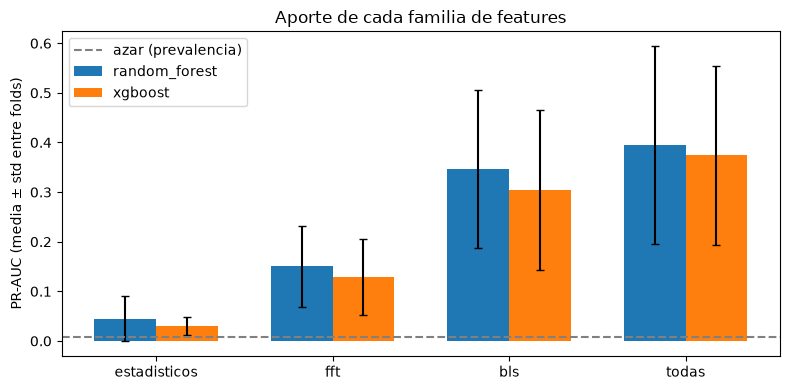

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ancho = 0.35
fams = list(FEATURE_SETS)
for k, modelo in enumerate(MODELS):
    medias = [folds_all[(modelo, f)].pr_auc.mean() for f in fams]
    stds = [folds_all[(modelo, f)].pr_auc.std() for f in fams]
    ax.bar(np.arange(len(fams)) + k * ancho, medias, ancho, yerr=stds, capsize=3, label=modelo)
ax.axhline(y_train.mean(), color='gray', ls='--', label='azar (prevalencia)')
ax.set_xticks(np.arange(len(fams)) + ancho / 2)
ax.set_xticklabels(fams)
ax.set_ylabel('PR-AUC (media ± std entre folds)')
ax.set_title('Aporte de cada familia de features')
ax.legend()
plt.tight_layout()
plt.savefig('../results/05_ablacion_features.png', dpi=120)
plt.show()

## 3. Test oficial (5 planetas) con IC 95% por bootstrap

Modelos entrenados con todo train y todas las features.

In [4]:
cols = select_columns(F_train, 'todas')
for modelo, make in MODELS.items():
    m = make().fit(F_train[cols].to_numpy(), y_train)
    print('==', modelo)
    print(report_test(y_test, m.predict_proba(F_test[cols].to_numpy())[:, 1]).round(3), '\n')

== random_forest


           valor  ic95_inf  ic95_sup
recall     0.400     0.000     0.800
precision  1.000     0.000     1.000
f1         0.571     0.000     0.889
pr_auc     0.580     0.158     1.000 

== xgboost


           valor  ic95_inf  ic95_sup
recall     0.600     0.200     1.000
precision  0.500     0.167     1.000
f1         0.545     0.182     0.889
pr_auc     0.673     0.287     1.000 



## Conclusiones

- **Las features físicas importan.** Con solo estadísticos genéricos, el PR-AUC en CV es 0,03–0,05 (cerca del piso del azar, 0,007, pero muy bajo). Con las 6 features BLS sube a 0,31–0,35 y con todas a ~0,37–0,39: unas **50 veces el azar** y ~8 veces los estadísticos solos. Esto respalda la hipótesis central de la propuesta.
- **FFT aporta poco por sí sola** (0,13–0,15), pero mejor que los estadísticos. Al sumarla al BLS, la mejora (0,347 -> 0,394 en RF, 0,305 -> 0,374 en XGBoost) es menor que la desviación entre folds (~0,16–0,20), así que **no podemos afirmar** que aporte; es un punto a revisar en la ablación final.
- **RF y XGBoost rinden parecido** en PR-AUC (0,394 vs 0,374, diferencia dentro del ruido). Cambia su comportamiento al umbral 0,5: XGBoost (con `scale_pos_weight`) detecta más planetas (recall 0,32) con precisión 0,38; Random Forest es más conservador (recall 0,09, precisión 0,56). Como recall, precisión y F1 dependen del umbral, **PR-AUC es la métrica principal**; ajustar el umbral queda como trabajo pendiente.
- **Alta incertidumbre.** La desviación entre folds es grande (~0,2) porque cada fold tiene ~7 planetas. En el test oficial (5 planetas) XGBoost obtiene PR-AUC 0,67 con IC 95% [0,29; 1,00] y Random Forest 0,58 [0,16; 1,00]: los intervalos se solapan casi por completo, por lo que no hay evidencia de que un modelo sea mejor.
- **Limitaciones:** hiperparámetros sin ajustar (valores razonables fijos), una sola configuración del BLS (períodos 0,5–30 d, cadencia supuesta de 30 min) y el test oficial con solo 5 positivos.